In [1]:
import json
import math
import matplotlib.pyplot as plt


def plotSolution(data,solution):

    # Charger le GeoJSON
    with open("countries.geo.json") as f:
        dataCountries = json.load(f)

    # get some data
    minVisiDuration = data['minVisiDuration']
    AOIs = data['AOIs']
    accesses = data['Accesses']
    satPasses = data['Passes']
    
    # get the booking strategy
    bookings = solution['Bookings']
    bookings.sort(key=lambda item: satPasses[item["passId"]]['startDate'])    
    print("Bookings:")
    for booking in bookings:
        print(booking)
    
    # show the passes used
    ncols = 3
    nrows = math.ceil(len(solution['Bookings']) / ncols)
    fig, axs = plt.subplots(nrows=nrows,ncols=ncols, figsize=(30,30))
    axs = axs.flatten()

    i = 0
    for booking in solution['Bookings']:
        passId = booking["passId"]
        satPass = satPasses[passId]
        ax = axs[i]
        
        # Dessiner les frontières
        for feature in dataCountries["features"]:
            geometry = feature["geometry"]
    
            if geometry["type"] == "Polygon":
                for coords in geometry["coordinates"]:
                    xs, ys = zip(*coords)
                    ax.fill(xs, ys, facecolor="lightgray", edgecolor="black", linewidth=0.5)

            elif geometry["type"] == "MultiPolygon":
                for polygon in geometry["coordinates"]:
                    for coords in polygon:
                        xs, ys = zip(*coords)
                        ax.fill(xs, ys, facecolor="lightgray", edgecolor="black", linewidth=0.5)

        
        ax.set_xlim(-9, 13)
        ax.set_ylim(38, 56)
        ax.set_title("Pass #{} [{},{}]".format(passId,satPass['startDate'],satPass['endDate']))
        ax.plot([aoi['lon'] for aoi in AOIs], [aoi['lat'] for aoi in AOIs], 'kx')

        # show the reservations
        xpoints = []
        ypoints = []
        colors = []
        for accessId in satPass['accessIds']:
            access = accesses[accessId]
            aoi = AOIs[access['aoiId']]
            xpoints.append(aoi['lon'])
            ypoints.append(aoi['lat'])
            if (booking['bookingStart'] <= access['end'] - minVisiDuration) and (access['start'] + minVisiDuration <= booking['bookingEnd']):
                colors.append('r')
            else:
                colors.append('b')       
        ax.scatter(xpoints,ypoints,marker='o',c=colors)
        
        i = i + 1


plt.show()



In [15]:
import random
import json

# import the data

dataFile = open('data/data12.json')  
data = json.load(dataFile)
accesses = data['Accesses']
obsRequests = data['ObservationRequests'];
nObsRequests = len(obsRequests)
satPasses = data['Passes'];

# a very basic solver

satisfied = [False for i in range(nObsRequests)]
nObsRequestsToCover = nObsRequests
nPasses = len(satPasses)
remainingSatPassesIds = list(range(nPasses))
random.shuffle(remainingSatPassesIds)
selectedPassIds = []
for i in remainingSatPassesIds:
    # try to select the ith path
    satPass = satPasses[i]
    keepPass = False
    for accessId in satPass['accessIds']:
        access = accesses[accessId]
        for j in range(nObsRequests):
            obsRequest = obsRequests[j]
            if not satisfied[j] and accessId in obsRequest['accessIds']:
                satisfied[j] = True
                keepPass = True
                nObsRequestsToCover -= 1
                
    if keepPass:
        selectedPassIds.append(i)
            
    if nObsRequestsToCover == 0:
        break


print("selectedPasses:", selectedPassIds)
print("nSelectedPasses:", len(selectedPassIds))

# export the solution to json
bookings = []
for i in selectedPassIds:
    satPass = satPasses[i]
    bookings.append({"passId": i, "passStart": satPass['start'], "passEnd": satPass['end'], "bookingStart": (satPass['start'] + 60), "bookingEnd": (satPass['end'] - 60)})
jsonString = json.dumps({"Bookings": bookings})
jsonFile = open("mySolution.json", "w")
jsonFile.write(jsonString)
jsonFile.close()


selectedPasses: [5, 40, 6, 9, 32, 17, 33, 53, 4, 61, 22, 58]
nSelectedPasses: 12


Bookings:
{'passId': 4, 'passStart': 2807, 'passEnd': 3094, 'bookingStart': 2867, 'bookingEnd': 3034}
{'passId': 5, 'passStart': 3295, 'passEnd': 3437, 'bookingStart': 3355, 'bookingEnd': 3377}
{'passId': 6, 'passStart': 3748, 'passEnd': 3945, 'bookingStart': 3808, 'bookingEnd': 3885}
{'passId': 9, 'passStart': 5777, 'passEnd': 6101, 'bookingStart': 5837, 'bookingEnd': 6041}
{'passId': 17, 'passStart': 11293, 'passEnd': 11607, 'bookingStart': 11353, 'bookingEnd': 11547}
{'passId': 22, 'passStart': 14759, 'passEnd': 14982, 'bookingStart': 14819, 'bookingEnd': 14922}
{'passId': 32, 'passStart': 21960, 'passEnd': 22144, 'bookingStart': 22020, 'bookingEnd': 22084}
{'passId': 33, 'passStart': 22326, 'passEnd': 22618, 'bookingStart': 22386, 'bookingEnd': 22558}
{'passId': 40, 'passStart': 26206, 'passEnd': 26426, 'bookingStart': 26266, 'bookingEnd': 26366}
{'passId': 53, 'passStart': 34208, 'passEnd': 34533, 'bookingStart': 34268, 'bookingEnd': 34473}
{'passId': 58, 'passStart': 36782, 'pass

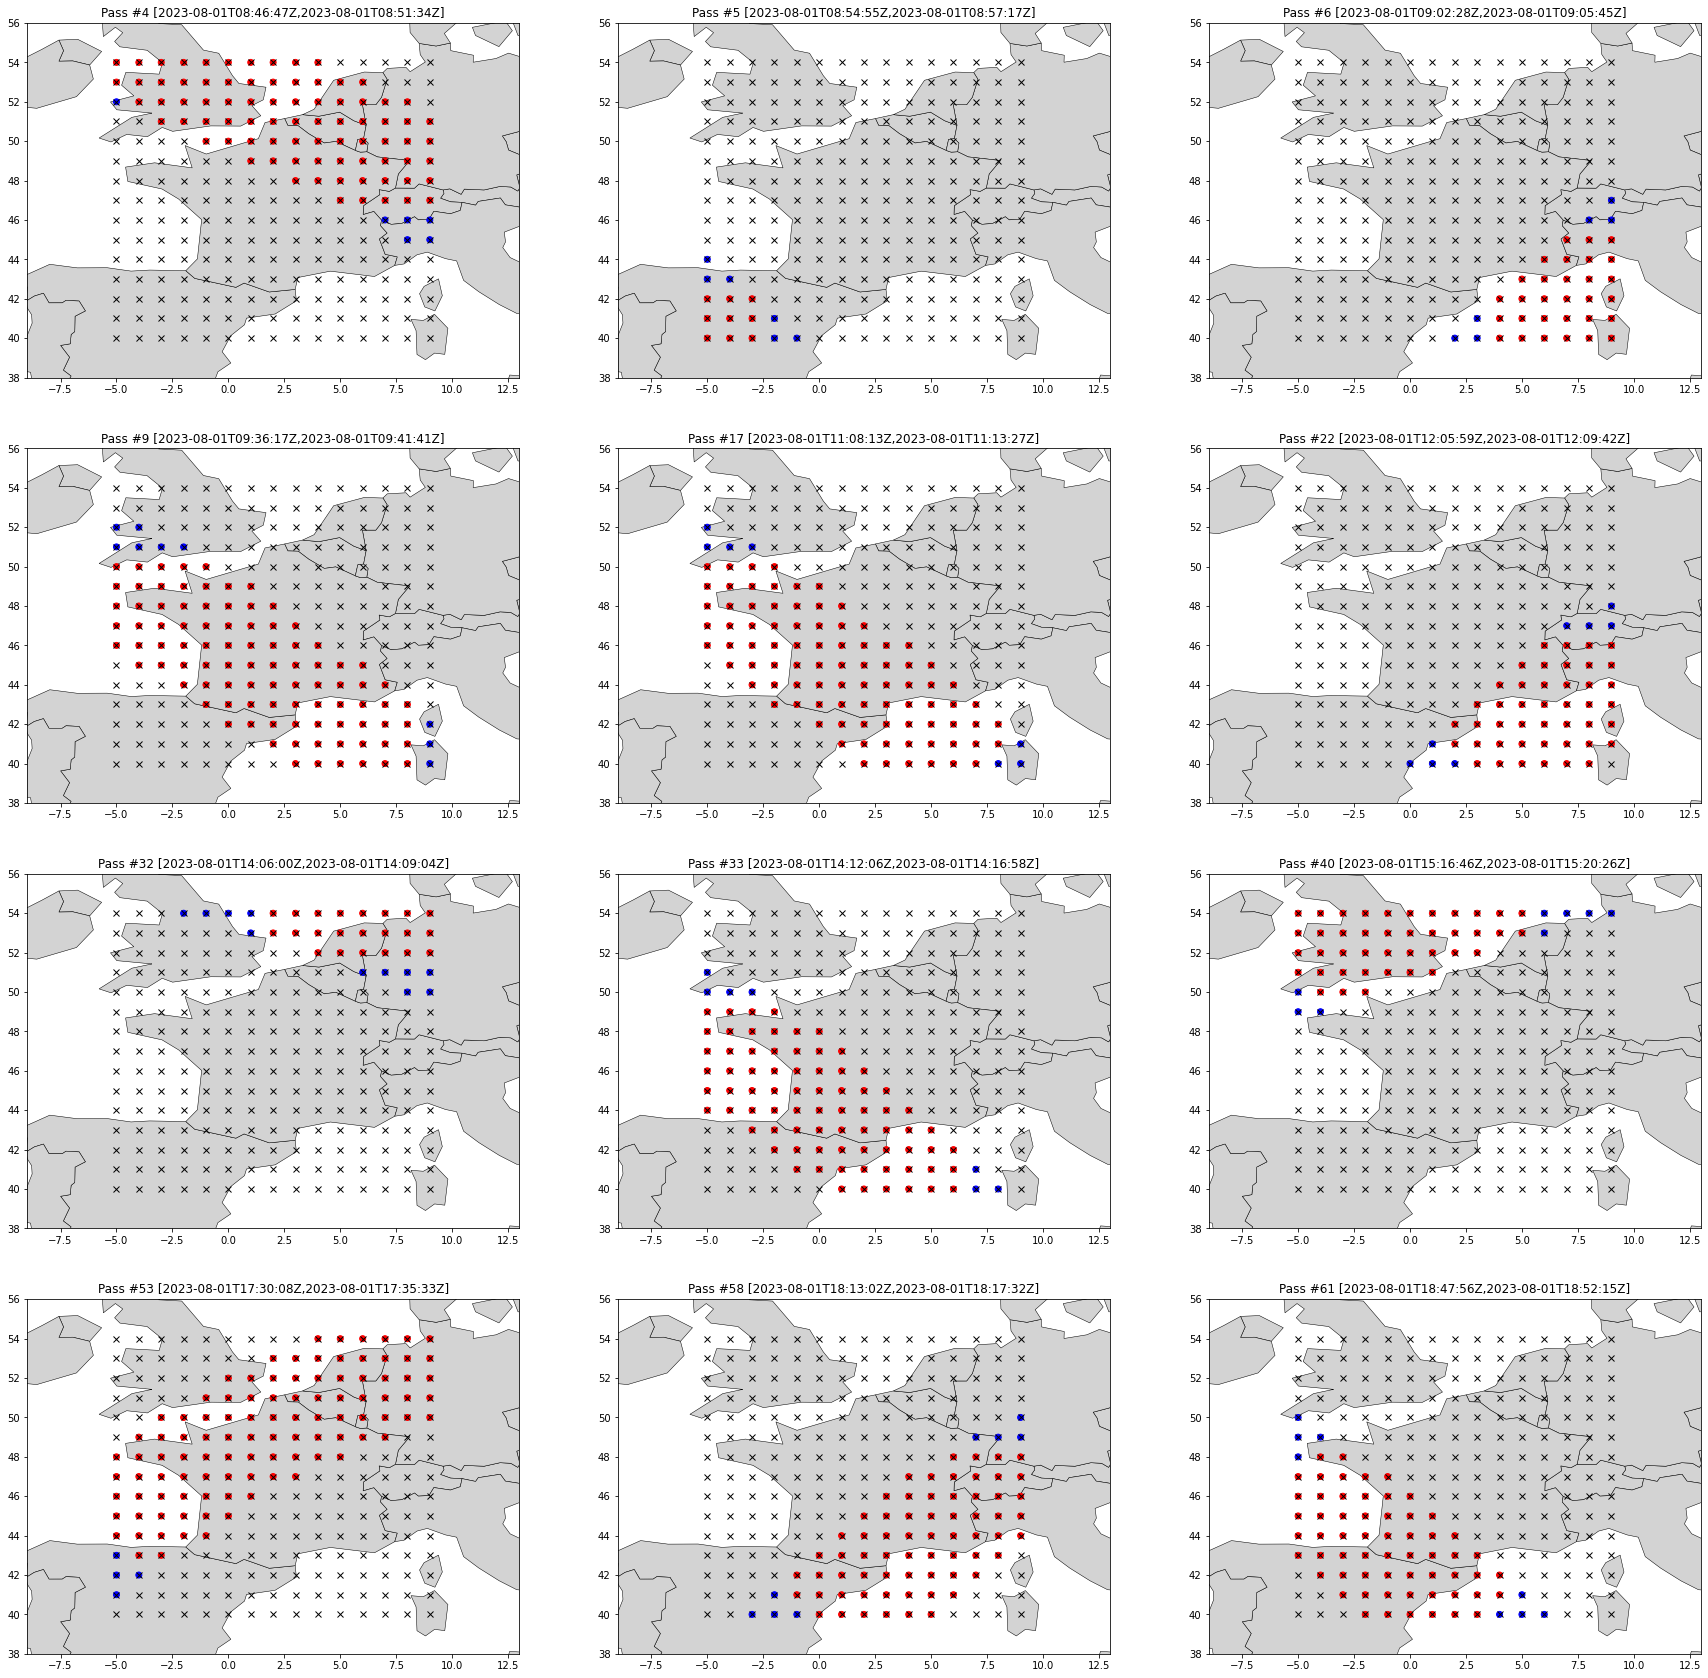

In [17]:
# import the solution
solutionFile = open('mySolution.json')  
solution = json.load(solutionFile)
plotSolution(data,solution)

In [4]:
accesses = data['Accesses']

print(accesses[10])

{'passId': 26, 'start': 17649, 'end': 17716, 'aoiId': 0}


In [5]:
print(accesses[10]['passId'])

26
